# plot heat map from mass balance (.dat)

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap

# import seaborn as sns
# plt.style.use('default')

import h5py as h5
import glob
import matplotlib.gridspec as gridspec
import datetime
from datetime import timedelta
from scipy import interpolate, stats
import os
import re
from natsort import natsorted, ns, natsort_keygen
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from shapely.geometry.polygon import Polygon
from scipy.stats.kde import gaussian_kde
import pickle
from textwrap import wrap

/tmp/ipykernel_389926/1976063767.py:24: DeprecationWarning: Please use `gaussian_kde` from the `scipy.stats` namespace, the `scipy.stats.kde` namespace is deprecated.
  from scipy.stats.kde import gaussian_kde


In [2]:
def batch_time_to_delta(origin, x, time_format):
    y = []
    for ix in x:
        temp_y = abs(datetime.strptime(
            ix, time_format) - origin).total_seconds()
        y.append(temp_y)
    y = np.asarray(y)
    return(y)

def batch_delta_to_time(origin, x, time_format, delta_format):
    y = []
    for ix in x:
#         ix = np.asscalar(ix)
        if delta_format == "hours":
            temp_y = origin + timedelta(hours=ix)
        elif delta_format == "days":
            temp_y = origin + timedelta(days=ix)
        elif delta_format == "minutes":
            temp_y = origin + timedelta(minutes=ix)
        elif delta_format == "weeks":
            temp_y = origin + timedelta(weeks=ix)
        elif delta_format == "seconds":
            temp_y = origin + timedelta(seconds=ix)
        elif delta_format == "microseconds":
            temp_y = origin + timedelta(microseconds=ix)
        elif delta_format == "milliseconds":
            temp_y = origin + timedelta(milliseconds=ix)
        else:
            print("Sorry, this naive program only solve single time unit")
        y.append(temp_y.strftime(time_format))
    y = np.asarray(y)
#     y = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in y]
    return(y)

In [3]:
def natural_sort(l): 
    convert = lambda text: int(text) if text.isdigit() else text.lower() 
    alphanum_key = lambda key: [ convert(c) for c in re.split('([0-9]+)', key) ] 
    return sorted(l, key = alphanum_key)  

### read river section information

In [4]:
fname_material_h5 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID-river.h5'
material_file = h5.File(fname_material_h5, "r")

In [5]:
def triangle_area_3d(ABC):
    # convert points to numpy array
    A = np.array(ABC[0])
    B = np.array(ABC[1])
    C = np.array(ABC[2])
    
    # calculate vectors AB and AC
    AB = B-A
    AC = C-A
    
    # compute the cross product of AB and AC
    cross_product = np.cross(AB, AC)
    
    # Calculate the area of the triangle
    area = 0.5*np.linalg.norm(cross_product)
    
    return area

In [6]:
vertex_coord = material_file['Domain']['Vertices']              # (x, y, z) coordinates

mass1_sections = [s for s, s in enumerate(
    list(material_file["Regions"].keys())) if "Mass1" in s]
group_order = np.argsort(np.asarray(
    [x[6:] for x in mass1_sections]).astype(float))
mass1_sections = [mass1_sections[i] for i in group_order]

section_area = np.zeros(len(mass1_sections))

# Assume material_file and mass1_sections are correctly defined
for isection in range(len(mass1_sections)):    
    bc_vertex_ids = material_file['Regions'][mass1_sections[isection]]['Vertex Ids'][:,1:4]   # (x, y, z) index
    for vertex_ids in bc_vertex_ids:
        bc_vertex_coord = vertex_coord[sorted(vertex_ids - 1),:]
        section_area[isection] += triangle_area_3d(bc_vertex_coord)
#    print(f"number {isection} section area: {section_area[isection]}")

### read mass1 coordinates 

In [7]:
fname_mass1_coord = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mass1/Mass1_datum_shift.csv'
section_coord = np.genfromtxt(fname_mass1_coord, delimiter=",", skip_header=1)

# subtract last mass1 location to get length for each segment
mass1_length = section_coord[:, 4] - section_coord[-1, 4]   # unit: km

In [18]:
# add three lines to contour indicating mass1 location
line1 = section_coord[0, 1:3] / 1000
line2 = section_coord[int(len(section_coord[:, 1]) / 2), 1:3] / 1000
line3 = section_coord[-1, 1:3] / 1000
line1_x = [line1[0]] * 2
line1_y = [line1[1] - 5, line1[1] + 5]
line2_x = [line2[0] - 5, line2[0] + 5]
line2_y = [line2[1]] * 2
line3_x = [line3[0] - 5, line3[0] + 5]
line3_y = [line3[1]] * 2

### read mass balance data

In [8]:
fname_mass_dat = '/pscratch/sd/z/zc727/model_iso_perm/HFR-iso-perm-mas.dat'       # isotropic model
#fname_mass_dat = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/perm_all_except_bsalt-mas.dat'   # all permeability change
#fname_mass_dat = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/perm_only_alluvium-mas.dat'     # only alluvium permeability change

mass_file = open(fname_mass_dat, "r")
mass_data = mass_file.readlines()
mass_header = mass_data[0].replace('"', '').split(",")
mass_header = list(filter(None, mass_header))
mass_data = [x.split(" ") for x in mass_data[1:]]
mass_data = [list(filter(None, x)) for x in mass_data]
mass_data = np.asarray(mass_data).astype(float)

### find columns of desired mass1 columns

In [9]:
# e.g River_40 Water Mass [kg]
mass_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg]" in s)]
# e.g River_40 Water Mass [kg/h]
flux_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg/h" in s)]

In [10]:
# get total river mass/flux across the river bed for each time step (6h)
total_mass = np.sum(mass_data[:, mass_index], axis=1).flatten()
total_flux = np.sum(mass_data[:, flux_index], axis=1).flatten()

In [11]:
# shift mass when restart happened, new starting mass would shift to zero
diff_total_mass = abs(np.diff(total_mass))
restart_index = np.arange(len(diff_total_mass))[diff_total_mass > 2e10]  # select 2e10 as a threshold

# add mass at restart check point to all after time steps
for i_restart_index in restart_index:
    total_mass[(i_restart_index + 1):len(total_mass)] = total_mass[(
        i_restart_index + 1):len(total_mass)] + total_mass[restart_index]

### plot river stage

In [12]:
start_time = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")

time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

selected_ticks = [
    "2011-02-25 00:00:00",
    "2011-04-30 00:00:00",
    "2011-07-04 00:00:00",
    "2011-08-18 00:00:00",
    "2011-10-17 00:00:00"
    ]
selected_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in selected_ticks]

### import rivers tage from generated mass1 datum files

In [13]:
fname_river_bc = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'
datum_files = glob.glob(fname_river_bc + "Datum*.txt")                        # 1h interval
datum_files = natural_sort(datum_files)

In [14]:
river_north_datum = pd.read_table(datum_files[0], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_middle_datum = pd.read_table(datum_files[(len(datum_files)-1)//2], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_south_datum = pd.read_table(datum_files[-1], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])

date_origin = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
river_north_datum['time'] = batch_delta_to_time(date_origin, river_north_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_middle_datum['time'] = batch_delta_to_time(date_origin, river_middle_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_south_datum['time'] = batch_delta_to_time(date_origin, river_south_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
# datum_time = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in datum_time]

In [15]:
river_north_datum['time'] = river_north_datum['time'].apply(pd.to_datetime)
river_middle_datum['time'] = river_middle_datum['time'].apply(pd.to_datetime)
river_south_datum['time'] = river_south_datum['time'].apply(pd.to_datetime)

In [27]:
print(river_middle_datum)

                      time           x           y        wl
0      2007-01-01 00:00:00  584264.626  142212.554  109.5307
1      2007-01-01 01:00:00  584264.626  142212.554  109.5407
2      2007-01-01 02:00:00  584264.626  142212.554  109.5607
3      2007-01-01 03:00:00  584264.626  142212.554  109.6007
4      2007-01-01 04:00:00  584264.626  142212.554  109.6407
...                    ...         ...         ...       ...
112484 2019-10-31 20:00:00  584264.626  142212.554  109.0007
112485 2019-10-31 21:00:00  584264.626  142212.554  109.0007
112486 2019-10-31 22:00:00  584264.626  142212.554  109.0307
112487 2019-10-31 23:00:00  584264.626  142212.554  109.1507
112488 2019-11-01 00:00:00  584264.626  142212.554  109.3407

[112489 rows x 4 columns]


### plot 6h-smooth river stage

In [28]:
print(river_middle_datum.loc[::6,:])

                      time           x           y        wl
0      2007-01-01 00:00:00  584264.626  142212.554  109.5307
6      2007-01-01 06:00:00  584264.626  142212.554  109.6907
12     2007-01-01 12:00:00  584264.626  142212.554  109.5807
18     2007-01-01 18:00:00  584264.626  142212.554  109.5207
24     2007-01-02 00:00:00  584264.626  142212.554  109.5407
...                    ...         ...         ...       ...
112464 2019-10-31 00:00:00  584264.626  142212.554  109.3607
112470 2019-10-31 06:00:00  584264.626  142212.554  110.0207
112476 2019-10-31 12:00:00  584264.626  142212.554  109.3607
112482 2019-10-31 18:00:00  584264.626  142212.554  109.0307
112488 2019-11-01 00:00:00  584264.626  142212.554  109.3407

[18749 rows x 4 columns]


In [29]:
print(time_ticks)

[datetime.datetime(2011, 1, 1, 0, 0), datetime.datetime(2012, 1, 1, 0, 0), datetime.datetime(2013, 1, 1, 0, 0), datetime.datetime(2014, 1, 1, 0, 0), datetime.datetime(2015, 1, 1, 0, 0), datetime.datetime(2016, 1, 1, 0, 0)]


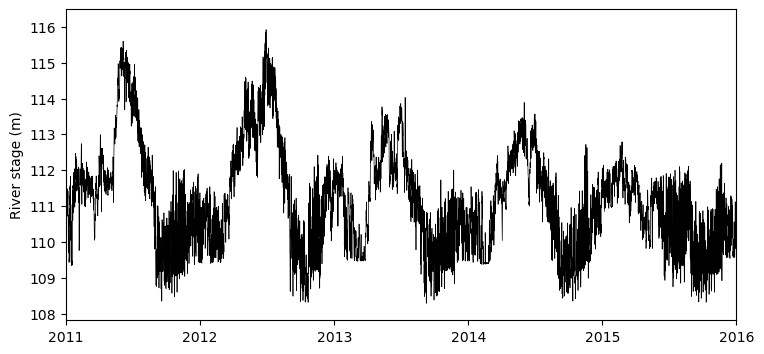

In [30]:
# Plotting
fig, ax1 = plt.subplots()

# Plot the data using matplotlib directly
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color='black', linewidth=0.5)

ax1.set_ylabel('River stage (m)')
ax1.set_xlabel('')

# Set the ticks and format
ax1.set_xticks(time_ticks)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.set_xlim([time_ticks[0], time_ticks[-1]])

# Adjust tick labels
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=0, ha='center')

fig.tight_layout()
fig.set_size_inches(8, 3.5)

plt.show()

### plot river stage for individual year

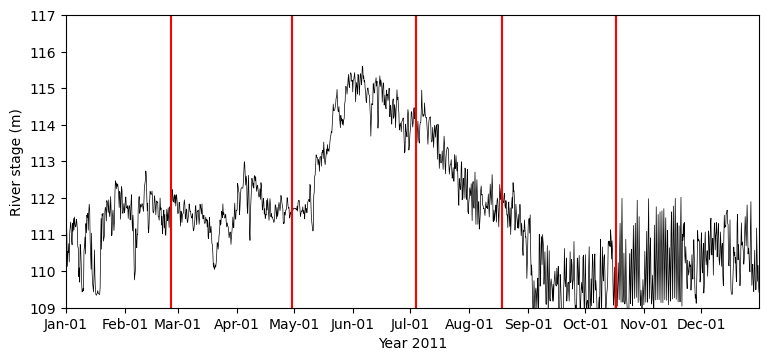

In [31]:
fig, ax1 = plt.subplots(1, 1)

# Plot the filtered data
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color='black', linewidth=0.5)

# Add vertical lines for the selected times
for itime in selected_ticks:
    ax1.axvline(itime, color='red', linestyle='-')

ax1.set_ylabel('River stage (m)')
ax1.set_xlabel('Year 2011')

# Set major ticks as months and format them
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b-%d'))

# Adjust limits for better visualization
ax1.set_ylim([109, 117])
ax1.set_xlim([datetime.datetime(2011, 1, 1), datetime.datetime(2011, 12, 31)])

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=0, ha='center')

fig.tight_layout()
fig.set_size_inches(8, 3.5)

plt.show()

### plot 5d-smoothed river stage

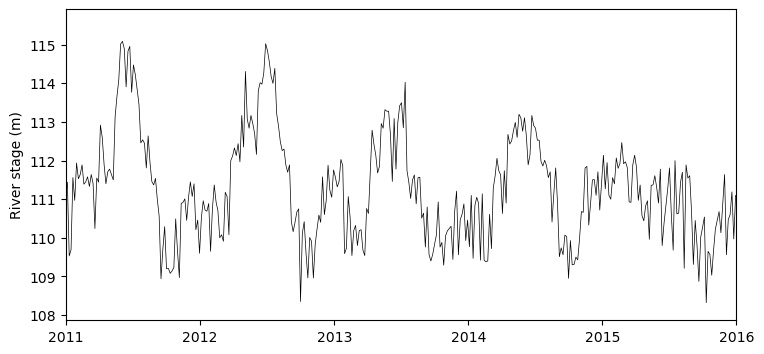

In [32]:
fig, ax1 = plt.subplots(1, 1)

# river_north_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)
ax1.plot(river_middle_datum.loc[::120, 'time'], river_middle_datum.loc[::120, 'wl'],color= 'black',linewidth = 0.5)
# river_south_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)

ax1.set_ylabel('River stage (m)')
ax1.set_xlabel('')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
#ax1.xaxis.set_tick_params('labelbottom')

ax1.set_xlim([time_ticks[0], time_ticks[-1]])
plt.setp( ax1.xaxis.get_majorticklabels(), rotation=0, ha = 'center' )

fig.tight_layout()
fig.set_size_inches(8, 3.5)

plt.show()

# plot flux heat map

### plot finger flux--isotropic model

In [ ]:
fname_mass_dat = '/pscratch/sd/z/zc727/model_iso_perm/HFR-iso-perm-mas.dat'       # isotropic model

mass_file = open(fname_mass_dat, "r")
mass_data = mass_file.readlines()
mass_header = mass_data[0].replace('"', '').split(",")
mass_header = list(filter(None, mass_header))
mass_data = [x.split(" ") for x in mass_data[1:]]
mass_data = [list(filter(None, x)) for x in mass_data]
mass_data = np.asarray(mass_data).astype(float)

In [ ]:
# find columns of desired mass1 colmns
# e.g River_40 Water Mass [kg]
mass_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg]" in s)]
# e.g River_40 Water Mass [kg/h]
flux_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg/h" in s)]

In [16]:
# plot fingerprint plots
simu_time = mass_data[:, 0]
real_time = batch_delta_to_time(
    date_origin, simu_time, "%Y-%m-%d %H:%M:%S", "hours")
real_time = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time]
plot_time = [
    "2011-01-01 00:00:00",
    "2016-01-01 00:00:00"]
plot_time = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in plot_time]

In [17]:
time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

In [77]:
# print(mass_header)

In [18]:
flux_array = mass_data[:, flux_index]                       # kg/h
flux_array = np.asarray(flux_array) / 1000 * 24             # convert to m^3/d
for itime in range(len(real_time)):
    flux_array[itime, :] = flux_array[itime, :] / section_area   # convert to m/d

In [37]:
print(np.shape(real_time))
print(np.shape(mass1_length[35:]))
print(np.shape(mass1_length[34:-1]))
print(np.shape(flux_array))
print(np.min(flux_array[:,0]))
print(np.shape(section_area))

(18747,)
(325,)
(325,)
(18747, 325)
-0.24333189799750204
(325,)


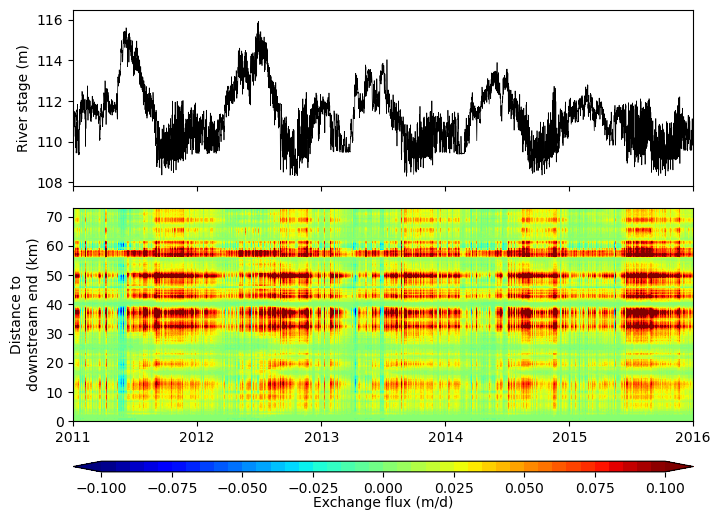

In [19]:
%matplotlib inline
# plot finger flux
# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
fig = plt.figure()

gs = gridspec.GridSpec(2, 1, height_ratios=[2,3])
gs.update(hspace = 0.1) # adjust vertical spacing b/w subplots
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)

# river_north_datum_s.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)
ax1.plot(river_middle_datum.loc[::6,'time'], river_middle_datum.loc[::6,'wl'],color= 'black',linewidth = 0.5)
# river_south_datum_s.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)
# ax1.set_yticks(np.arange(0, 76, 10))
ax1.set_ylabel('River stage (m)')
ax1.xaxis.set_tick_params(labelbottom=False)
# ax1.set_title('River stage from upstream to downstream')

# plt.xticks(time_ticks, rotation=0, horizontalalignment = "center")
# ax1.set_xticks(time_ticks)

# ax1.set_xlim([time_ticks[0], time_ticks[-1]])


cf1 = ax2.contourf(real_time,
                   0.5 * (mass1_length[35:] + mass1_length[34:-1]),
                   -np.transpose(flux_array),                            
                   cmap=plt.cm.jet,
                   levels=np.arange(-0.1, 0.105, 0.005),
                   extend="both",
                   )
ylabel = '\n'.join(wrap("Distance to downstream end (km)", 20))
ax2.set_ylabel(ylabel)
# ax2.set_title("Exchange flux of weekly boundary")
ax2.set_xticks(time_ticks)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.set_yticks(np.arange(0, 76, 10))
ax2.set_ylim([0, 73])
ax2.set_xlim([time_ticks[0], time_ticks[-1]])

divider = make_axes_locatable(ax2)
cax = divider.new_vertical(size="5%", pad=0.4, pack_start=True)
fig.add_axes(cax)
cb1 = fig.colorbar(cf1, cax=cax, orientation="horizontal")

# cb1 = plt.colorbar(cf1, extend="both", orientation = "horizontal", pad = 0.2)
cb1.ax.set_xlabel("Exchange flux (m/d)", labelpad=0.3)

ax1.minorticks_off()
# fig.suptitle("Finger flux plot for weekly boundary", fontsize = 12)
# fig.tight_layout()
fig.set_size_inches(8, 6)

## plot finger flux--model with all permeability change

In [20]:
fname_mass_dat_2 = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/perm_all_except_basalt-mas.dat'   # all permeability change

# read mass balance data
mass_file_2 = open(fname_mass_dat_2, "r")
mass_data_2 = mass_file_2.readlines()
mass_header = mass_data_2[0].replace('"', '').split(",")
mass_header = list(filter(None, mass_header))
mass_data_2 = [x.split(" ") for x in mass_data_2[1:]]
mass_data_2 = [list(filter(None, x)) for x in mass_data_2]
mass_data_2 = np.asarray(mass_data_2).astype(float)

In [21]:
# find columns of desired mass1 colmns
# e.g River_40 Water Mass [kg]
mass_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg]" in s)]
# e.g River_40 Water Mass [kg/h]
flux_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg/h" in s)]

In [22]:
# plot fingerprint plots
simu_time = mass_data_2[:, 0]
real_time_2 = batch_delta_to_time(
    date_origin, simu_time, "%Y-%m-%d %H:%M:%S", "hours")
real_time_2 = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time_2]
plot_time = [
    "2011-01-01 00:00:00",
    "2016-01-01 00:00:00"]
plot_time = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in plot_time]
time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

In [23]:
flux_array_2 = mass_data_2[:, flux_index]
flux_array_2 = np.asarray(flux_array_2) / 1000 * 24 # convert to m/d
for itime in range(len(real_time_2)):
    flux_array_2[itime, :] = flux_array_2[itime, :] / section_area

**plot finger flux with river stage**

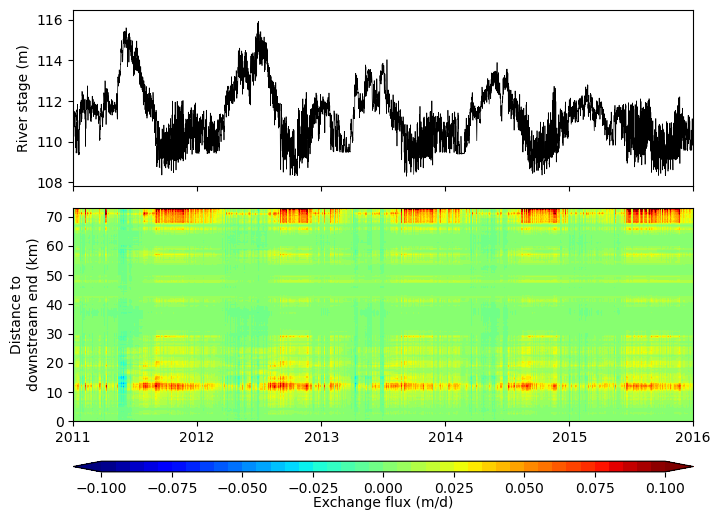

In [24]:
%matplotlib inline
# plot finger flux
# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
fig = plt.figure()
gs = gridspec.GridSpec(2, 1, height_ratios=[2,3])
gs.update(hspace = 0.1) # adjust vertical spacing b/w subplots
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)

# river_north_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)
ax1.plot(river_middle_datum.loc[::6,'time'], river_middle_datum.loc[::6,'wl'],color= 'black',linewidth = 0.5)
# river_south_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)

ax1.set_ylabel('River stage (m)')
ax1.xaxis.set_tick_params(labelbottom=False)

cf1 = ax2.contourf(real_time_2,
                   0.5 * (mass1_length[35:] + mass1_length[34:-1]),
                   -np.transpose(flux_array_2),
                   cmap=plt.cm.jet,
                   levels=np.arange(-0.1, 0.105, 0.005),
                   extend="both",
                   )
# ax2.set_ylabel("")
ylabel = '\n'.join(wrap("Distance to downstream end (km)", 20))
ax2.set_ylabel(ylabel)
# ax2.set_title("Exchange flux of weekly boundary")
ax2.set_xticks(time_ticks)
ax2.set_yticks(np.arange(0, 76, 10))
ax2.set_ylim([0, 73])
ax2.set_xlim([time_ticks[0], time_ticks[-1]])

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

divider = make_axes_locatable(ax2)
cax = divider.new_vertical(size="5%", pad=0.4, pack_start=True)
fig.add_axes(cax)
cb1 = fig.colorbar(cf1, cax=cax, orientation="horizontal")

# cb1 = plt.colorbar(cf1, extend="both", orientation = "horizontal", pad = 0.2)
cb1.ax.set_xlabel("Exchange flux (m/d)", labelpad=0.3)

# fig.suptitle("Finger flux plot for hourly boundary", fontsize = 12)
ax1.minorticks_off()
# fig.tight_layout()
fig.set_size_inches(8, 6)

## plot finger flux--model with only sediment permeability change

In [25]:
fname_mass_dat_3 = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/perm_only_alluvium-mas.dat'     # only alluvium permeability change

# read mass balance data
mass_file_3 = open(fname_mass_dat_3, "r")
mass_data_3 = mass_file_3.readlines()
mass_header = mass_data_3[0].replace('"', '').split(",")
mass_header = list(filter(None, mass_header))
mass_data_3 = [x.split(" ") for x in mass_data_3[1:]]
mass_data_3 = [list(filter(None, x)) for x in mass_data_3]
mass_data_3 = np.asarray(mass_data_3).astype(float)

In [26]:
# find columns of desired mass1 colmns
# e.g River_40 Water Mass [kg]
mass_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg]" in s)]
# e.g River_40 Water Mass [kg/h]
flux_index = [i for i, s in enumerate(mass_header) if (
    "River" in s and "Water" in s and "kg/h" in s)]

In [27]:
# plot fingerprint plots
simu_time = mass_data_3[:, 0]
real_time_3 = batch_delta_to_time(
    date_origin, simu_time, "%Y-%m-%d %H:%M:%S", "hours")
real_time_3 = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time_3]
plot_time = [
    "2011-01-01 00:00:00",
    "2016-01-01 00:00:00"]
plot_time = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in plot_time]
time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

In [28]:
flux_array_3 = mass_data_3[:, flux_index]
flux_array_3 = np.asarray(flux_array_3) / 1000 * 24 # convert to m/d
for itime in range(len(real_time_3)):
    flux_array_3[itime, :] = flux_array_3[itime, :] / section_area

**plot finger flux with river stage**

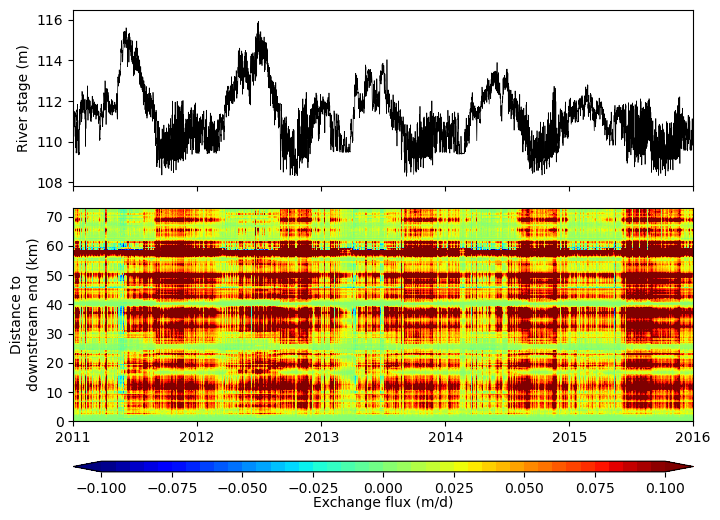

In [29]:
%matplotlib inline
# plot finger flux
# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
fig = plt.figure()
gs = gridspec.GridSpec(2, 1, height_ratios=[2,3])
gs.update(hspace = 0.1) # adjust vertical spacing b/w subplots
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)

# river_north_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)
ax1.plot(river_middle_datum.loc[::6,'time'], river_middle_datum.loc[::6,'wl'],color= 'black',linewidth = 0.5)
# river_south_datum.plot(x='time', y='wl',color= 'black', linewidth = 0.5, ax=ax1, legend=None)

ax1.set_ylabel('River stage (m)')
ax1.xaxis.set_tick_params(labelbottom=False)

cf1 = ax2.contourf(real_time_3,
                   0.5 * (mass1_length[35:] + mass1_length[34:-1]),
                   -np.transpose(flux_array_3),
                   cmap=plt.cm.jet,
                   levels=np.arange(-0.1, 0.105, 0.005),
                   extend="both",
                   )
ylabel = '\n'.join(wrap("Distance to downstream end (km)", 20))
ax2.set_ylabel(ylabel)
ax2.set_xticks(time_ticks)
ax2.set_yticks(np.arange(0, 76, 10))
ax2.set_ylim([0, 73])
ax2.set_xlim([time_ticks[0], time_ticks[-1]])

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

divider = make_axes_locatable(ax2)
cax = divider.new_vertical(size="5%", pad=0.4, pack_start=True)
fig.add_axes(cax)
cb1 = fig.colorbar(cf1, cax=cax, orientation="horizontal")

cb1.ax.set_xlabel("Exchange flux (m/d)", labelpad=0.3)

ax1.minorticks_off()
fig.set_size_inches(8, 6)

## plot net flux difference between isotropic model and model with all permeability change

In [30]:
# Calculate the difference, avoiding division by zero, and suppress warnings for division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    flux_array_diff_2 = np.where(
        np.abs(flux_array) != 0,
        (np.abs(flux_array_2) - np.abs(flux_array)) / np.abs(flux_array) * 100,
        0
    )

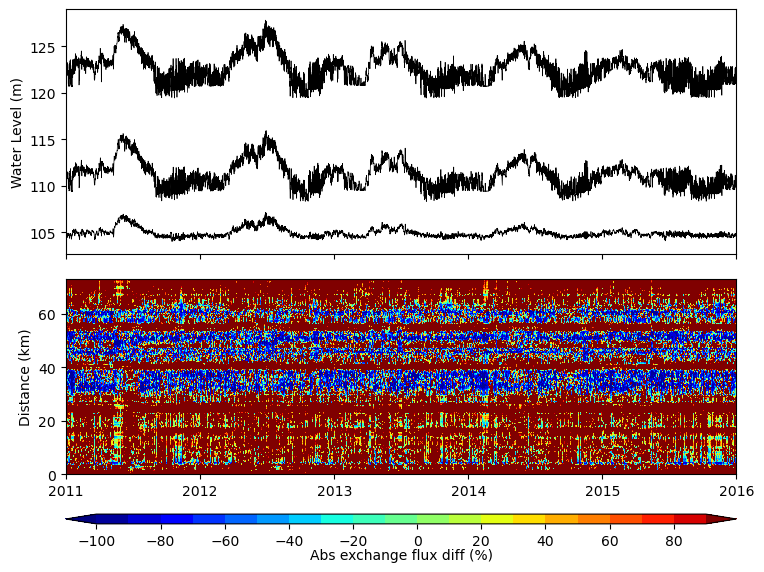

In [31]:
%matplotlib inline

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(river_north_datum.loc[::6, 'time'], river_north_datum.loc[::6, 'wl'],color= 'black', linewidth = 0.5)
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color= 'black',linewidth = 0.5)
ax1.plot(river_south_datum.loc[::6,'time'], river_south_datum.loc[::6,'wl'],color= 'black', linewidth = 0.5)

ax1.set_ylabel('Water Level (m)')
ax1.xaxis.set_tick_params(labelbottom=False)

# gs = gridspec.GridSpec(1, 1)
# fig = plt.figure()
# ax1 = fig.add_subplot(gs[0, 0])
cf1 = ax2.contourf(real_time_2,
                   0.5 * (mass1_length[35:] + mass1_length[34:-1]),
                   np.transpose(flux_array_diff_2),
                   cmap=plt.cm.jet,
                   levels=np.arange(-100, 100, 10),
                   extend="both",
                   vmin = -100, vmax = 100,
                   )

# ax2.imshow(np.transpose(flux_array_diff_num), cmap=cm.gist_rainbow)
# ax2.set_ylabel("")
ax2.set_ylabel("Distance (km)", wrap = True)
ax2.set_xticks(time_ticks)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.set_ylim([0, 73])
ax2.set_xlim([time_ticks[0], time_ticks[-1]])


divider = make_axes_locatable(ax2)
cax = divider.new_vertical(size="5%", pad=0.4, pack_start=True)
fig.add_axes(cax)
cb1 = fig.colorbar(cf1, cax=cax, orientation="horizontal")

# cb1 = plt.colorbar(cf1, extend="both", orientation = "horizontal", pad = 0.2)
cb1.ax.set_xlabel("Abs exchange flux diff (%)", labelpad=0.3)

# fig.suptitle("Finger flux plot for hourly boundary", fontsize = 12)
ax1.minorticks_off()
fig.tight_layout()
fig.set_size_inches(8, 6)


## plot net flux difference between isotropic model and model with only sediment permeability change

In [32]:
# Calculate the difference, avoiding division by zero, and suppress warnings for division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    flux_array_diff_3 = np.where(
        np.abs(flux_array) != 0,
        (np.abs(flux_array_3) - np.abs(flux_array)) / np.abs(flux_array) * 100,
        0
    )

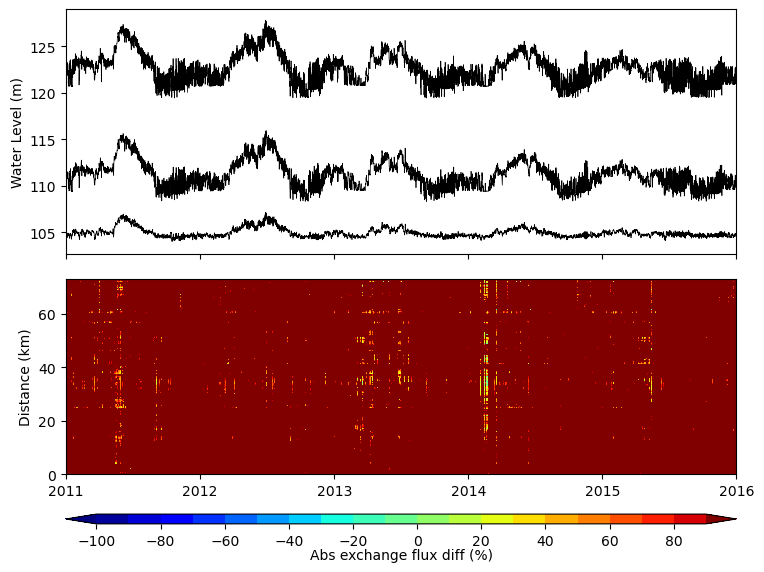

In [33]:
%matplotlib inline

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(river_north_datum.loc[::6, 'time'], river_north_datum.loc[::6, 'wl'],color= 'black', linewidth = 0.5)
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color= 'black',linewidth = 0.5)
ax1.plot(river_south_datum.loc[::6,'time'], river_south_datum.loc[::6,'wl'],color= 'black', linewidth = 0.5)

ax1.set_ylabel('Water Level (m)')
ax1.xaxis.set_tick_params(labelbottom=False)

# gs = gridspec.GridSpec(1, 1)
# fig = plt.figure()
# ax1 = fig.add_subplot(gs[0, 0])
cf1 = ax2.contourf(real_time_2,
                   0.5 * (mass1_length[35:] + mass1_length[34:-1]),
                   np.transpose(flux_array_diff_3),
                   cmap=plt.cm.jet,
                   levels=np.arange(-100, 100, 10),
                   extend="both",
                   vmin = -100, vmax = 100,
                   )

# ax2.imshow(np.transpose(flux_array_diff_num), cmap=cm.gist_rainbow)
# ax2.set_ylabel("")
ax2.set_ylabel("Distance (km)", wrap = True)
ax2.set_xticks(time_ticks)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.set_ylim([0, 73])
ax2.set_xlim([time_ticks[0], time_ticks[-1]])


divider = make_axes_locatable(ax2)
cax = divider.new_vertical(size="5%", pad=0.4, pack_start=True)
fig.add_axes(cax)
cb1 = fig.colorbar(cf1, cax=cax, orientation="horizontal")

# cb1 = plt.colorbar(cf1, extend="both", orientation = "horizontal", pad = 0.2)
cb1.ax.set_xlabel("Abs exchange flux diff (%)", labelpad=0.3)

# fig.suptitle("Finger flux plot for hourly boundary", fontsize = 12)
ax1.minorticks_off()
fig.tight_layout()
fig.set_size_inches(8, 6)

# plot flux exchanges across riverbed snapshots

**import river geometry**

In [17]:
fname_river_geo = '/global/cfs/cdirs/m1800/pin/Reach_scale_model/data/river_geometry_manual_v2.csv'

river_geo = pd.read_csv(fname_river_geo)

river_geo['x'] = river_geo['x']/1000          # convert to km
river_geo['y'] = river_geo['y']/1000          # convert to km

polygon = Polygon(river_geo.loc[:, ["x", "y"]].values)
river_x,river_y = polygon.exterior.xy

**visualize the triangular mesh in watershed geometry**

In [68]:
section_coord_sub = section_coord[34:,0:3]     # (idx, x, y)  

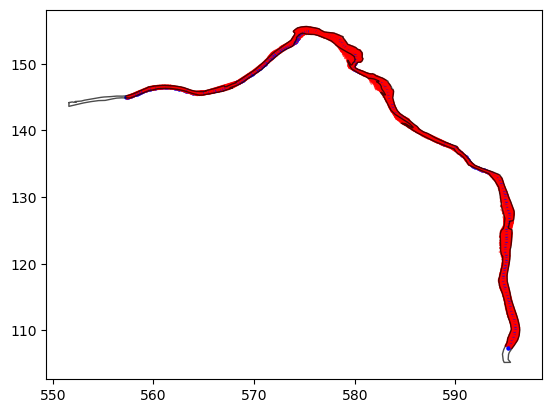

number of cell in riverbed 19476


In [80]:
# Setup the figure and axis
fig, ax = plt.subplots()

# Plot the river geometry
ax.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)

vertex_coord = material_file['Domain']['Vertices']              # (x, y, z) coordinates

num_cell = 0
# Assume material_file and mass1_sections are correctly defined
for isection in range(len(mass1_sections)):
    datum_coord = section_coord_sub[isection,1:]/1000   # convert to km (x, y) coordinates of datum
    ax.scatter(datum_coord[0], datum_coord[1], color='b', alpha=1, s=5)
    
    bc_vertex_ids = material_file['Regions'][mass1_sections[isection]]['Vertex Ids'][:,1:4]   # (x, y, z) index
    num_cell += len(bc_vertex_ids)
    
    for vertex_ids in bc_vertex_ids:
        bc_vertex_coord = vertex_coord[sorted(vertex_ids - 1),:]/1000        # convert to km
        
        # Create and plot polygon
        polygon = plt.Polygon(bc_vertex_coord[:, :-1], closed=True, facecolor='none', edgecolor='r', alpha=0.5)
        ax.add_patch(polygon)

# Display the plot
plt.show()

print(f'number of cell in riverbed {num_cell}')

In [ ]:
# The target datetime
target_time_1 = np.datetime64("2011-01-01 00:00:00")
target_time_2 = np.datetime64("2015-12-31 00:00:00")

# Find index
index_1 = np.where(real_time == target_time_1)[0]  # Use [0] to get index array
index_2 = np.where(real_time == target_time_2)[0]
print("Index of the target time 1:", index_1)
print("Index of the target time 2:", index_2)

/tmp/ipykernel_2229239/2010717655.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  for itime in np.arange(index_1, index_1+1, 1):  # every 20 steps


2011-01-01 00:00:00


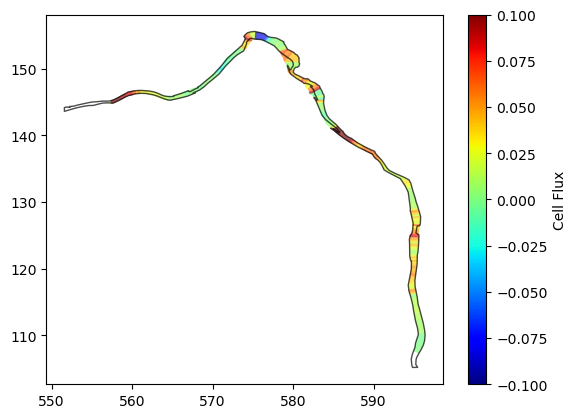

In [96]:
from matplotlib.patches import Polygon
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Assuming river_x, river_y, material_file, mass1_sections, and flux_array are defined
fig, ax = plt.subplots()

# Plot the river geometry
ax.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)

# Set the desired color range for cell_flux
vmin, vmax = -0.1, 0.1
cmap = plt.cm.jet  # You can choose other colormaps, e.g., 'plasma', 'inferno'
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

# Create a color bar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Set an empty array just for the color bar
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Cell Flux')

vertex_coord = material_file['Domain']['Vertices']  # (x, y, z) coordinates

# Iterate over time and sections
for itime in np.arange(index_1, index_1+1, 1):  # every 20 steps
    print(real_time[itime])
    for isection in range(len(mass1_sections)):
        cell_flux = flux_array[itime, isection]  
        bc_vertex_ids = material_file['Regions'][mass1_sections[isection]]['Vertex Ids'][:, 1:4]
        for vertex_ids in bc_vertex_ids:
            bc_vertex_coord = vertex_coord[sorted(vertex_ids - 1), :] / 1000  # Convert to km
            
            # Get the face color based on cell_flux
            face_color = cmap(norm(cell_flux))
            
            # Create and plot polygon with flux-based color
            polygon = Polygon(bc_vertex_coord[:, :-1], closed=True, facecolor=face_color, edgecolor='none', alpha=1.0)
            ax.add_patch(polygon)

# Display the plot
plt.show()